# All Rényi orders against Shannon

Gathers every α whose 10 deterministic full-span seeds are on disk (0.5, 0.7, 0.9, 1.0, 1.5, 2.0) and builds the appendix sensitivity table. It trains nothing, so it is safe to re-run at any time. Any α that is not finished yet is listed and skipped.

- **Confirmatory:** α\* = 0.7 against Shannon, the test of record. The numbers match section 3.2 of `run_alpha_0.7.ipynb`.
- **Sensitivity:** every other α against Shannon. The Holm column adjusts the one-sided GW p-values for testing several α against the same baseline.
- **Model Confidence Set** (Hansen–Lunde–Nason, 90%) over every finished α at once, on daily test-span QLIKE. This answers which orders cannot be told apart from the best one without picking a pair in advance.

## 0. Settings and what is on disk

In [1]:
import os, sys, time
from pathlib import Path
HERE = Path.cwd()
if not (HERE / "alpha_common.py").exists():        # launched from final_results/ or the repo root
    for cand in (HERE / "alpha_runs", HERE / "final_results" / "alpha_runs"):
        if (cand / "alpha_common.py").exists():
            HERE = cand
            break
sys.path.insert(0, str(HERE))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
import alpha_common as ac
hf = ac.hf

# Smoke mode: tiny budgets, separate folders, numbers mean nothing.  Only for
# checking the notebook runs end to end.  Set RUN_ALPHA_SMOKE=1 to enable.
SMOKE = os.environ.get("RUN_ALPHA_SMOKE") == "1"
SEEDS, RUNS_ROOT, N_JOBS, OVERRIDES = hf.SEEDS, hf.RUNS_DIR, ac.N_JOBS, {}
TABLES_ROOT = HERE / "tables"
if SMOKE:
    SEEDS, RUNS_ROOT, N_JOBS = (0, 1), HERE / "runs_smoke", 2
    TABLES_ROOT = HERE / "tables_smoke"
    OVERRIDES = dict(epochs=2, finetune_epochs=1, n_shuffles=5)

TABLES = TABLES_ROOT
TABLES.mkdir(parents=True, exist_ok=True)
data = hf.prepare_data(hf.make_config())
cfg = hf.make_config()
changes = pd.DatetimeIndex(data["changes"])

st = ac.status(ac.ALL_ALPHAS, SEEDS, RUNS_ROOT)
display(st)
ALPHAS = [a for a in ac.ALL_ALPHAS if st.loc[a, "complete"]]
assert 1.0 in ALPHAS, "the Shannon baseline is not complete"
print("included:", ALPHAS, "  not finished:", [a for a in ac.ALL_ALPHAS if a not in ALPHAS])
runs = {a: ac.load(a, SEEDS, RUNS_ROOT) for a in ALPHAS}

,model,seeds_done,of,complete,deterministic,missing
alpha,,,,,,
0.5,HR-ETE-GNN(a=0.5),10,10,True,10,[]
0.7,HR-ETE-GNN(a=0.7),10,10,True,10,[]
0.9,HR-ETE-GNN(a=0.9),10,10,True,10,[]
1.0,H-ETE-GNN,10,10,True,10,[]
1.5,HR-ETE-GNN(a=1.5),10,10,True,10,[]
2.0,HR-ETE-GNN(a=2),10,10,True,10,[]


included: [0.5, 0.7, 0.9, 1.0, 1.5, 2.0]   not finished: []


## 1. Paper metrics over 2006–2024, every α

In [2]:
per_seed = ac.per_seed_metrics(runs)
per_seed.to_csv(TABLES / "all_alphas_full_span_per_seed.csv", index=False)
fmt = ac.paper_table(per_seed)
fmt.to_csv(TABLES / "all_alphas_full_span_paper_metrics.csv")
display(fmt)

,RMSE,MAE,MAPE,Correlation,HitRatio,QLIKE
Model,,,,,,
H-ETE-GNN,0.6088 ± 0.1711,0.2372 ± 0.0243,13.2048 ± 0.7045,0.8655 ± 0.0221,0.5532 ± 0.0024,0.1347 ± 0.1602
HR-ETE-GNN(a=0.5),0.5864 ± 0.0520,0.2868 ± 0.0080,17.4098 ± 0.2710,0.8422 ± 0.0239,0.5358 ± 0.0029,2.4603 ± 3.6106
HR-ETE-GNN(a=0.7),0.6471 ± 0.1051,0.2901 ± 0.0129,17.4513 ± 0.3819,0.8137 ± 0.0599,0.5373 ± 0.0015,7.6863 ± 12.3184
HR-ETE-GNN(a=0.9),0.6479 ± 0.1746,0.2758 ± 0.0170,15.9717 ± 0.5166,0.8327 ± 0.0388,0.5415 ± 0.0018,5.5043 ± 5.9729
HR-ETE-GNN(a=1.5),0.6214 ± 0.1903,0.2161 ± 0.0229,12.0425 ± 0.5216,0.8692 ± 0.0385,0.5581 ± 0.0025,0.3644 ± 0.8549
HR-ETE-GNN(a=2),0.7443 ± 0.2386,0.2385 ± 0.0207,13.0762 ± 0.4576,0.8382 ± 0.0461,0.5540 ± 0.0043,1.0388 ± 2.7527
"Lee & Cho (2025), H-ETE-GNN",0.1623,0.1024,6.6555,0.9605,0.7206,-


## 2. Test span: each α against Shannon

In [3]:
def holm(p):
    p = pd.Series(p, dtype=float); order = p.sort_values().index; m = len(p)
    adj = (p[order] * np.arange(m, 0, -1)).cummax().clip(upper=1.0)
    return adj.reindex(p.index)

val = pd.read_csv(ac.FINAL / "tables" / "stage1_alpha_selection.csv", index_col="alpha")
rows, results = [], {}
for a in ALPHAS:
    if a == 1.0:
        continue
    results[a] = ac.compare_to_shannon(a, runs[1.0], runs[a], data, cfg.tickers, SEEDS)
    rows.append(results[a]["summary"])
sens = pd.DataFrame(rows).set_index("alpha")
sens.insert(1, "role", ["confirmatory (alpha*)" if a == ac.ALPHA_STAR else "sensitivity" for a in sens.index])
sens.insert(2, "val_MSE", [val["MSE_mean"].get(a, np.nan) for a in sens.index])
sens.insert(3, "val_QLIKE", [val["QLIKE_mean"].get(a, np.nan) for a in sens.index])   # shown only; alpha* was picked on val_MSE
sens["GW_p_one_sided_Holm"] = holm(sens["GW_p_one_sided"]) if len(sens) else []
sens.to_csv(TABLES / "all_alphas_test_vs_shannon.csv")
display(sens.round(4))
print("val_MSE / val_QLIKE are blank for alpha = 0.5: it is below the alpha >= 0.6 floor and was never a candidate.")
print("alpha* was selected on val_MSE (the training loss); val_QLIKE played no part in the choice.")

,Model,role,val_MSE,val_QLIKE,test_QLIKE,test_QLIKE_shannon,QLIKE_improvement_pct,MSE_improvement_pct,GW_stat,GW_p_two_sided,GW_p_one_sided,DM_p_one_sided,GW_regime_p,seeds_won,n_seeds,ETFs_won_BH,GW_p_one_sided_Holm
alpha,,,,,,,,,,,,,,,,,
0.5,HR-ETE-GNN(a=0.5),sensitivity,NaN,NaN,0.0659,0.0347,-90.3101,-23.8514,427.7424,0.0000,1.0000,1.0,0.0000,2,10,2,1.0000
0.7,HR-ETE-GNN(a=0.7),confirmatory (alpha*),0.8269,0.1551,0.0693,0.0347,-99.9242,-19.6045,392.7703,0.0000,1.0000,1.0,0.0000,0,10,1,1.0000
0.9,HR-ETE-GNN(a=0.9),sensitivity,1.0628,0.1555,0.0589,0.0347,-70.0540,-28.6605,130.5400,0.0000,1.0000,1.0,0.0000,1,10,0,1.0000
1.5,HR-ETE-GNN(a=1.5),sensitivity,1.4794,0.1314,0.0247,0.0347,28.7837,7.5311,74.0099,0.0000,0.0000,0.0,0.0000,6,10,8,0.0000
2.0,HR-ETE-GNN(a=2),sensitivity,0.9295,0.1362,0.0316,0.0347,8.8165,-79.4067,6.6702,0.0098,0.0049,0.0,0.0034,5,10,5,0.0196


val_MSE / val_QLIKE are blank for alpha = 0.5: it is below the alpha >= 0.6 floor and was never a candidate.
alpha* was selected on val_MSE (the training loss); val_QLIKE played no part in the choice.


### 2.1 Hypothesis tests by α

One row per Rényi order: H0 is equal predictive ability with Shannon, and H1 is lower QLIKE for Rényi. α\* = 0.7 is the confirmatory test; the other orders are sensitivity results. The decision column uses the Holm-adjusted one-sided GW p-value at 5%. Written to `tables/hypothesis_tests_by_alpha.csv` and, ready to paste into the manuscript, `.md`.

In [ ]:
def fmt_p(x):
    return "<0.001" if x < 0.001 else f"{x:.3f}"

hyp = []
for a, r in sens.iterrows():
    h = results[a]["headline"]["value"]
    if r.GW_p_one_sided_Holm < 0.05:
        dec = "Reject H0: Renyi better"
    elif r.GW_p_two_sided < 0.05 and r.QLIKE_improvement_pct < 0:
        dec = "Fail to reject; Shannon significantly better"
    else:
        dec = "Fail to reject"
    hyp.append({
        "alpha": a, "role": r.role,
        "QLIKE Renyi": r.test_QLIKE, "QLIKE Shannon": r.test_QLIKE_shannon,
        "QLIKE change %": r.QLIKE_improvement_pct,
        "GW Wald": r.GW_stat, "GW p (2-sided)": r.GW_p_two_sided,
        "GW p (1-sided)": r.GW_p_one_sided, "GW p (1-sided, Holm)": r.GW_p_one_sided_Holm,
        "DM-HLN stat": h["DM (HLN) on QLIKE: stat"], "DM p (1-sided)": r.DM_p_one_sided,
        "MSE change %": r.MSE_improvement_pct, "DM on MSE p (1-sided)": h["DM on MSE: p one-sided"],
        "Cond. GW (regime) p": r.GW_regime_p, "Regime coef": h["GW regime coefficient"],
        "Regime coef p": h["GW regime coefficient p"],
        "ETFs better (BH q=0.10)": f"{int(r.ETFs_won_BH)}/10",
        "Seeds better": f"{int(r.seeds_won)}/{int(r.n_seeds)}",
        "Decision (5%)": dec,
    })
hyp = pd.DataFrame(hyp).set_index("alpha")
hyp.to_csv(TABLES / "hypothesis_tests_by_alpha.csv")

md = ["| α | Role | QLIKE (Rényi / Shannon) | Δ QLIKE | GW Wald | GW p two-sided | GW p one-sided | Holm p | "
      "DM-HLN (p) | Δ MSE (DM p) | Cond. GW regime p | Regime coef (p) | ETFs better | Seeds better | Decision |",
      "|" + "---|" * 15]
for a, r in hyp.iterrows():
    md.append(f"| {a:g} | {r['role']} | {r['QLIKE Renyi']:.4f} / {r['QLIKE Shannon']:.4f} | {r['QLIKE change %']:+.1f}% | "
              f"{r['GW Wald']:.1f} | {fmt_p(r['GW p (2-sided)'])} | {fmt_p(r['GW p (1-sided)'])} | "
              f"{fmt_p(r['GW p (1-sided, Holm)'])} | {r['DM-HLN stat']:.2f} ({fmt_p(r['DM p (1-sided)'])}) | "
              f"{r['MSE change %']:+.1f}% ({fmt_p(r['DM on MSE p (1-sided)'])}) | {fmt_p(r['Cond. GW (regime) p'])} | "
              f"{r['Regime coef']:+.4f} ({fmt_p(r['Regime coef p'])}) | {r['ETFs better (BH q=0.10)']} | "
              f"{r['Seeds better']} | {r['Decision (5%)']} |")
(TABLES / "hypothesis_tests_by_alpha.md").write_text("\n".join(md) + "\n", encoding="utf-8")
display(hyp[["role", "QLIKE change %", "GW p (2-sided)", "GW p (1-sided, Holm)", "Decision (5%)"]].round(4))

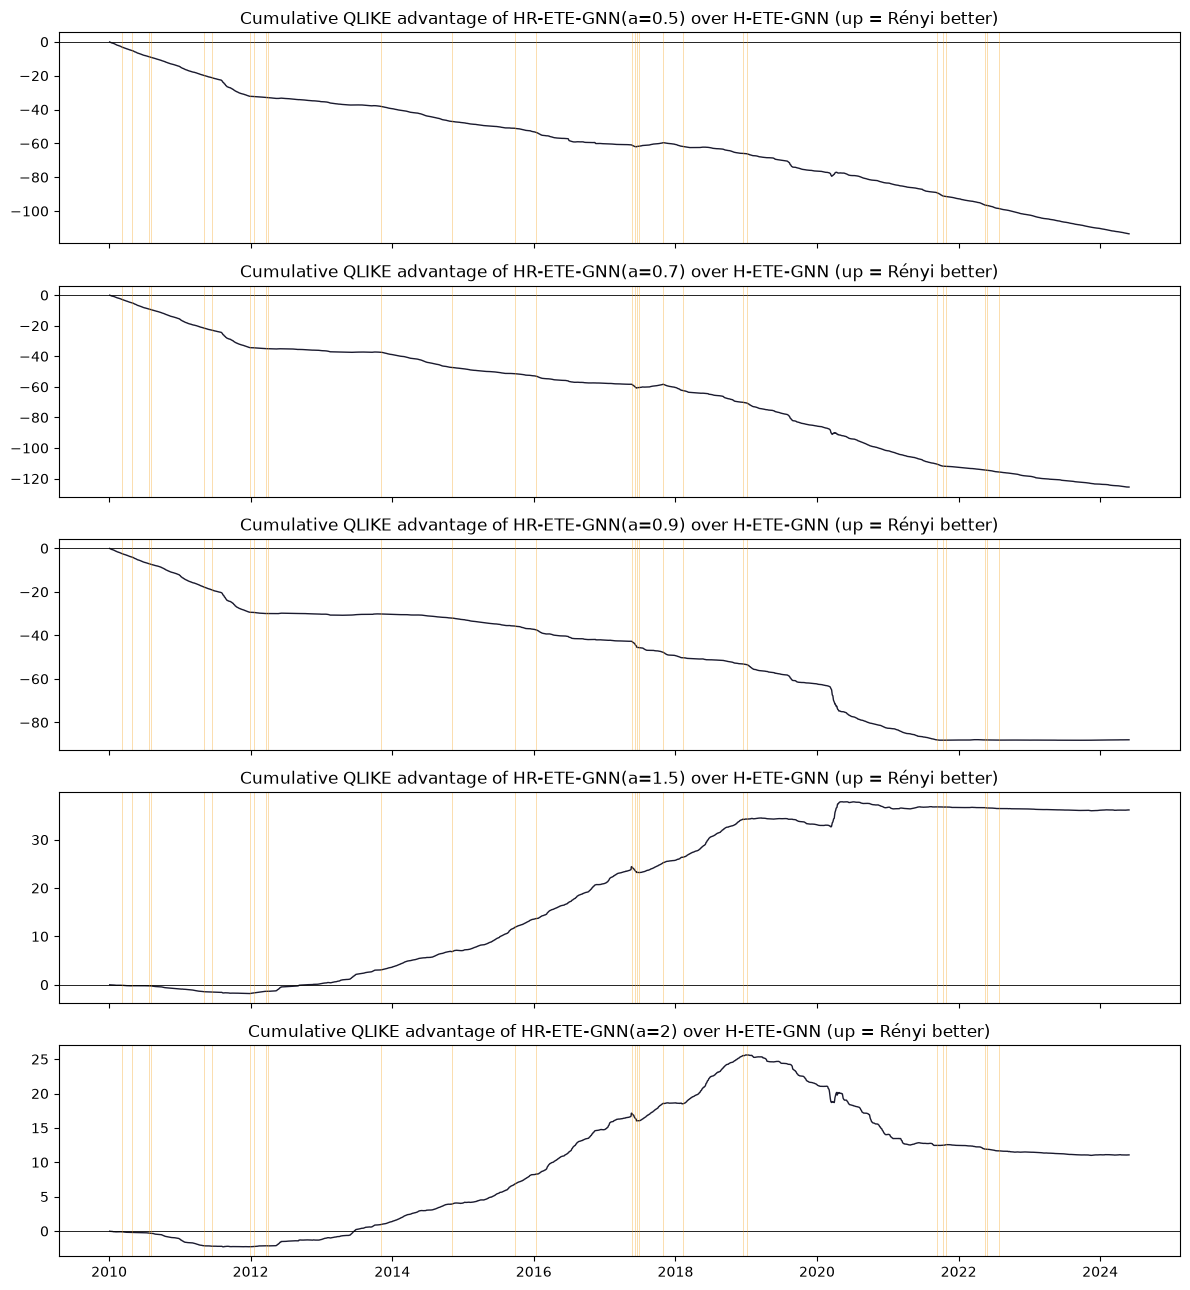

In [4]:
fig, ax = plt.subplots(len(results), 1, figsize=(12, 2.6 * max(1, len(results))), sharex=True, squeeze=False)
for k, (a, r) in enumerate(results.items()):
    ac.plot_cumulative(r, a, changes, ax=ax[k, 0])
plt.tight_layout(); plt.savefig(TABLES / "all_alphas_cumulative_qlike.png", dpi=150); plt.show()

## 3. Model Confidence Set over all orders (90%, test-span QLIKE)

In [5]:
losses = {hf.arm_label(a): ac.test_losses(runs[a], SEEDS)["qlike"].mean(axis=1) for a in ALPHAS}
mcs = ac.ts.model_confidence_set(losses, alpha=0.10, B=1000, seed=0)
mcs_tab = pd.DataFrame({"test_QLIKE": {k: v.mean() for k, v in losses.items()},
                        "MCS_p": mcs["p_values"]})
mcs_tab["in_90pct_MCS"] = mcs_tab.index.isin(mcs["included"])
mcs_tab = mcs_tab.sort_values("test_QLIKE")
mcs_tab.to_csv(TABLES / "all_alphas_mcs.csv")
display(mcs_tab.round(5))
print("90% MCS:", mcs["included"])

,test_QLIKE,MCS_p,in_90pct_MCS
HR-ETE-GNN(a=1.5),0.02468,1.000,True
HR-ETE-GNN(a=2),0.03160,0.001,False
H-ETE-GNN,0.03465,0.001,False
HR-ETE-GNN(a=0.9),0.05893,0.000,False
HR-ETE-GNN(a=0.5),0.06595,0.000,False
HR-ETE-GNN(a=0.7),0.06928,0.000,False


90% MCS: ['HR-ETE-GNN(a=1.5)']


## 4. Test QLIKE across α

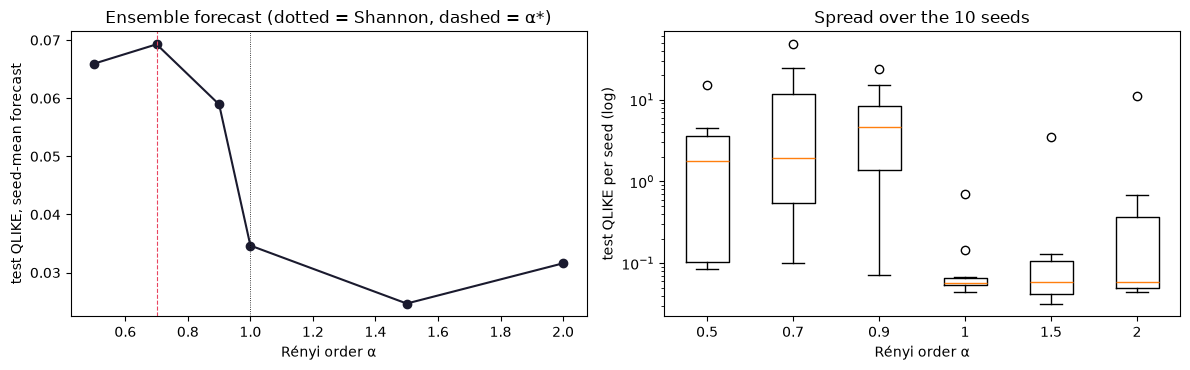

In [6]:
test = runs[1.0][SEEDS[0]]["dates"] > pd.Timestamp(hf.VAL_END)
seed_q = pd.DataFrame({a: [ac.qlike_mean(runs[a][s]["y_true"][test], runs[a][s]["y_pred"][test]) for s in SEEDS]
                       for a in ALPHAS}, index=list(SEEDS))
ens_q = pd.Series({a: losses[hf.arm_label(a)].mean() for a in ALPHAS})

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(ens_q.index, ens_q.values, "o-", color="#1a1a2e")
ax[0].axvline(1.0, color="k", lw=.6, ls=":"); ax[0].axvline(ac.ALPHA_STAR, color="#e94560", lw=.8, ls="--")
ax[0].set_xlabel("Rényi order α"); ax[0].set_ylabel("test QLIKE, seed-mean forecast")
ax[0].set_title("Ensemble forecast (dotted = Shannon, dashed = α*)")
ax[1].boxplot([seed_q[a] for a in ALPHAS]); ax[1].set_xticks(range(1, len(ALPHAS) + 1), [f"{a:g}" for a in ALPHAS])
ax[1].set_yscale("log"); ax[1].set_xlabel("Rényi order α"); ax[1].set_ylabel("test QLIKE per seed (log)")
ax[1].set_title("Spread over the 10 seeds")
plt.tight_layout(); plt.savefig(TABLES / "all_alphas_qlike_vs_alpha.png", dpi=150); plt.show()
seed_q.to_csv(TABLES / "all_alphas_test_qlike_per_seed.csv")